## Python for Research Data — Part 1
#### Introduction to Coding for STEM students · 60 minutes

Foundations: Colab · variables · numpy & pandas · loops · **writing your own functions**


---


| Part | What we do | Time |
|---|---|---|
| **0** | Introduction | 7 min |
| **1** | Colab tour + Python basics | 13 min |
| **2** | Basic operations and how to read an error message| 10 min |
| **3** |Guided experiment: clean a real river dataset, build box & violin plots | 15 min |
| **4** | 🚪 Breakout rooms: 5 bugs to fix, light-intensity dataset | 10 min |
| **5** | Q&A |  5 min |
| **[optional]** | bring your own data |  |



# 1 Colab

### The runtime — what you are actually using

When you press ▶ for the first time, Google hands you a **runtime**: a temporary Linux computer in a data centre, with Python already installed.

| | |
|---|---|
| **What you get** | ~12 GB RAM, ~100 GB disk, a CPU (free GPU/TPU under *Runtime → Change runtime type*) |
| **How long** | Disconnects after ~90 min idle, and after ~12 h in any case |
| **What survives a disconnect** | **Nothing.** Variables, uploaded files, installed packages — all gone. Your notebook text and code survive because they live in Google Drive |
| **Restart session** | Clears all variables, keeps your files |
| **Disconnect and delete runtime** | Throws the whole machine away — the true fresh start |

> **The practical rule:** anything you care about — a cleaned table, a figure — must be **saved and downloaded**, or written straight back to Google Drive. Treat the runtime as a bench you have to clear at the end of the day.

The `!` prefix runs a **shell** command instead of Python, so you can inspect that machine directly:

In [ ]:
# These are Linux commands — they work on the Colab runtime,
# and will say "command not found" if you run this notebook on your own laptop.
!python --version
!nvidia-smi -L      # lists a GPU, if you attached one
!free -g            # RAM, in gigabytes

## The interface

| Thing | What it does |
|---|---|
| **Cell** | A box holding either code or text. Everything happens in cells. |
| **▶ / `Shift + Enter`** | Run the cell and move to the next one |
| **`Ctrl/Cmd + Enter`** | Run the cell and stay put |
| **`+ Code` / `+ Text`** | Add a new cell |
| **Runtime → Restart session** | Wipe everything and start clean — your first move when things get weird or break |
| **Files 📁 (left sidebar)** | Temporary storage. **Deleted when you close the tab** — download anything you want to keep |

## Three rules that explain 90% of beginner confusion

1. **Order matters.** Cells run in the order *you press play*, not top to bottom. If you skip a cell, later cells will not find what they need.
2. **Memory persists.** A variable made in one cell is available in every other cell — until you restart the runtime.
3. **The last line prints itself.** Anything else needs `print()`.

A **library** (or package) is code someone else wrote so you do not have to. The five we need are **already installed in Colab**:

| Library | Nickname | Job |
|---|---|---|
| `pandas` | `pd` | Spreadsheets in code — load, filter, group |
| `numpy` | `np` | Fast maths on arrays |
| `matplotlib` | `plt` | The drawing engine |
| `seaborn` | `sns` | Beautiful statistical plots |
| `scipy.stats` | — | Hypothesis tests |

Anything else you install yourself with `pip`, Python's package manager:

```python
!pip install scikit-posthocs        # a package Colab does not ship with
!pip install "pandas==2.2.0"        # a specific version, when a tutorial needs one
!pip install package --quiet        # hide the wall of output
```

> **Two things to know.** Installs vanish when the runtime restarts, so keep the `!pip install` line at the top of your notebook. And if pip says *"restart the runtime"*, do it — Python only notices a new version of an already-loaded library after a restart.

Running the install for a package you already have is harmless — pip just says *already satisfied*.

In [ ]:
print('hello')

## 2 Basic operations and How to read a Python error
---

### The dataset

**COIL 1999 European river water-quality survey** — 200 water samples from rivers across Europe, each analysed for chemistry and algal content.

| Column | Meaning |
|---|---|
| `season`, `river_size`, `fluid_velocity` | Sampling context |
| `max_pH`, `min_O2` | pH and dissolved oxygen |
| `chloride`, `nitrate`, `ammonium`, `orthophosphate`, `phosphate` | Nutrient chemistry (mg L⁻¹) |
| **`chlorophyll_a`** | **Chlorophyll-a concentration (µg L⁻¹) — our headline measurement** |
| `alga_1` … `alga_7` | Abundance of 7 algal genera |

**Chlorophyll-a** is the standard proxy for algal biomass: more chlorophyll = more algae = a bloom risk. Our question:

> **What conditions favour algal blooms in rivers?**

*Source: [UCI Machine Learning Repository — COIL 1999 Competition Data](https://archive.ics.uci.edu/dataset/50/coil+1999+competition+data). Collected by the European Computational Intelligence Learning network.*

⚠️ This file is genuinely broken in places. That is why we chose it.
When code fails, Python prints a **traceback**. It looks intimidating. It is not.

```
Traceback (most recent call last)
  <ipython-input-4-9f2c> in <cell line: 1>()
  ----> 1 df["Chlorophyll"].mean()          ←  ② WHERE it broke
  ...
KeyError: 'Chlorophyll'                     ←  ① WHAT broke
```

> ### 🔑 Read a traceback **bottom to top**.
> 1. **Last line** = the error type and message. This is 90% of the answer.
> 2. **The arrow `---->`** = the exact line that failed.
> 3. Everything in between is Python's internal plumbing. Ignore it at first.

### The six errors you will meet today

| Error | Plain English | Usual cause |
|---|---|---|
| `SyntaxError` | "I can't even read this." | Missing `)`, `:` or quote |
| `NameError` | "I've never heard of that." | Typo, or you skipped the cell that made it |
| `KeyError` | "That column doesn't exist." | Wrong column name — check spelling **and case** |
| `TypeError` | "Wrong kind of thing." | Doing maths on text |
| `ValueError` | "Right kind, impossible value." | Converting `"XXXXXXX"` to a number |
| `AttributeError` | "That thing has no such command." | Typo in a method name |

And the seventh, the dangerous one:

| **No error at all** | The code ran perfectly and gave you the **wrong answer**. |
|---|---|

Only *you* can catch that last one — by sanity-checking every result.

In [ ]:
# Anything after a # is a comment — Python ignores it. Comments are for humans.

experiment = "Chlorophyll survey"      # text  (str)
n_samples  = 200                       # whole number (int)
mean_chl   = 13.5                      # decimal (float)
is_pilot   = False                     # True/False (bool)

print(experiment, "|", n_samples, "samples")
print("Mean chlorophyll-a:", mean_chl, "µg/L")

# f-strings drop variables straight into text — the {} are filled in
print(f"{experiment}: {n_samples} samples, mean {mean_chl:.1f} µg/L")

In [ ]:
# A list holds several values in order. Counting starts at ZERO.
readings = [2.1, 5.6, 20.7, 110.5, 0.4]

print("First reading :", readings[0])     # 0 = first!
print("Last reading  :", readings[-1])    # -1 = last
print("How many      :", len(readings))
print("Biggest       :", max(readings))
print("Average       :", sum(readings) / len(readings))

# A loop repeats an action for every item
for r in readings:
    if r > 10:
        print(f"  ⚠️  {r} µg/L — bloom territory")

### 🐞 Warm-up bug 1

Run the cell below. It will fail. **Read the last line first**, then fix it in place and re-run.

In [ ]:
# 🐞 BROKEN — fix me
species = ["Anabaena", "Microcystis", "Cladophora"]

for s in species
    print("Genus:", s)

<details>
<summary>💡 Hint</summary>

`SyntaxError: expected ':'` — Python is pointing at the `for` line. Every `for`, `if`, `def` and `while` line ends in a colon.
</details>

### 🐞 Warm-up bug 2

Same drill. Read the bottom line.

In [ ]:
# 🐞 BROKEN — fix me
total_chlorophyll = 0

for value in [2.1, 5.6, 20.7]:
    total_chlorophyll = total_chlorophyll + value

print("Total:", total_chlorophyl)

<details>
<summary>💡 Hint</summary>

`NameError: name 'total_chlorophyl' is not defined` — Python is not guessing. One letter is missing in `print()`. Long variable names are a trade-off: clear to read, easy to mistype.
</details>

---
# 3 · The experiment  ⏱ 15 min

## Our toolkit

| Library | Nickname | Job |
|---|---|---|
| `pandas` | `pd` | Spreadsheets in code — load, filter, group |
| `numpy` | `np` | Fast maths on arrays |
| `matplotlib` | `plt` | The drawing engine |
| `seaborn` | `sns` | Beautiful statistical plots |
| `scipy.stats` | — | Hypothesis tests |

All four are pre-installed in Colab. Run this once.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import kruskal, mannwhitneyu

# House style for every figure in this notebook
plt.rcParams.update({
    "font.size"          : 11,
    "axes.linewidth"     : 0.9,
    "axes.spines.top"    : False,
    "axes.spines.right"  : False,
    "figure.dpi"         : 110,
    "savefig.bbox"       : "tight",
    "savefig.dpi"        : 300,
})

# Our chlorophyll-inspired palettes
FLOW_ORDER = ["Low", "Medium", "High"]
FLOW_PAL   = {"Low": "#08605f", "Medium": "#3fa34d", "High": "#c5d86d"}   # deep water → algal green
SIZE_ORDER = ["Small", "Medium", "Large"]
SIZE_PAL   = {"Small": "#ffd166", "Medium": "#ef8354", "Large": "#8d3b72"}  # amber → plum

print("✅ Ready. pandas", pd.__version__, "| seaborn", sns.__version__)

## 3.1 Load the data

`pd.read_csv()` reads a CSV straight from a web address — no download, no file browser.

Run the cell. **It will not crash.** That is the problem.

In [ ]:
URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/coil-mld/analysis.data"

# 🐞 BROKEN — but it runs without complaining. Look hard at the output.
df = pd.read_csv(URL)

print("Shape (rows, columns):", df.shape)
df.head()

### 🔍 Work backwards

No traceback. So interrogate the result instead:

- The file has **200 samples**. How many rows did we get?
- Look at the **column names**. Are `winter`, `small_`, `8.00000` reasonable names for columns?

> **What happened:** `read_csv` assumes row 1 is a header of column names. This file has **no header** — so pandas ate our first data row and turned it into labels.

**Fix:** tell pandas there is no header, and supply the names ourselves.

In [ ]:
COLS = [
    "season", "river_size", "fluid_velocity",
    "max_pH", "min_O2", "chloride", "nitrate", "ammonium",
    "orthophosphate", "phosphate", "chlorophyll_a",
    "alga_1", "alga_2", "alga_3", "alga_4", "alga_5", "alga_6", "alga_7",
]

# ✅ FIXED
df = pd.read_csv(URL, header=None, names=COLS)

print("Shape:", df.shape)          # expect (200, 18)
df.head()

## 3.2 Look before you leap

Four commands you should run on **every** dataset, before anything else.

| Command | Question it answers |
|---|---|
| `df.shape` | How big? |
| `df.info()` | What type is each column, and how many values are missing? |
| `df.head()` | What does a row actually look like? |
| `df.describe()` | Are the numbers plausible? |

In [ ]:
df.info()

### 🔍 Stop and read that output

`Dtype` is the column's data type:

- `float64` = decimal number ✅ we can do maths
- `int64` = whole number ✅
- **`object` / `string` = text** ❌ maths will fail

Scroll the list. **Which columns are text when they clearly should be numbers?**

Every one of those is a landmine. Let's step on them.

## 3.3 🐞 Bug 3 — the column that isn't there

In [ ]:
# 🐞 BROKEN
df["chlorophyll"].median()

<details>
<summary>💡 Hint</summary>

`KeyError: 'Chlorophyll'` = "no column by that name". Python does **not** autocorrect and is **case-sensitive**.

Run `df.columns` to see the real names, then fix the spelling.
</details>

In [ ]:
# ✅ Check the real names before you type them
print(list(df.columns))

df["chlorophyll_a"].head()

## 3.4 🐞 Bug 4 — maths on text

In [ ]:
# 🐞 BROKEN
df["chlorophyll_a"].mean()

### 🔍 Work backwards from `TypeError`

`TypeError` means *"you asked for an operation this kind of data can't do."* You cannot average words.

But `chlorophyll_a` looked numeric in `head()`. So **one bad value has poisoned the whole column** — pandas types a column by its worst member.

Find the culprit: list the unique values and look for anything that isn't a number.

In [ ]:
# Detective work: what non-numeric values are hiding in there?
vals = df["chlorophyll_a"].unique()
print("Unique values (first 15):", vals[:15])

# to_numeric with errors="coerce" turns anything unconvertible into NaN.
# Rows where that happens are exactly our troublemakers.
suspects = df.loc[pd.to_numeric(df["chlorophyll_a"], errors="coerce").isna(), "chlorophyll_a"]
print("\nHow many bad entries:", len(suspects))
print("They look like:", suspects.unique())

## 3.5 🐞 Bug 5 — the brute-force fix that isn't

`XXXXXXX` is this dataset's code for *"measurement failed"*. The obvious move is to force the column to numbers.

In [ ]:
# 🐞 BROKEN
df["chlorophyll_a"].astype(float)

### 🔍 `ValueError` vs `TypeError`

- `TypeError` = **wrong kind** of thing (can't average text).
- `ValueError` = **right kind, impossible value**. `astype(float)` is happy to convert text — but `"XXXXXXX"` is not a number in any language.

**Fix:** tell `read_csv` up front that `XXXXXXX` means *missing*. Pandas then stores it as `NaN` (Not a Number), which every statistical function knows to skip.

This is the single most useful argument in `read_csv`.

In [ ]:
# ✅ FIXED — declare the missing-value code at load time
df = pd.read_csv(URL, header=None, names=COLS, na_values="XXXXXXX")

print("Missing values per column:")
print(df.isna().sum()[df.isna().sum() > 0])

print("\nchlorophyll_a dtype:", df["chlorophyll_a"].dtype)
print("Mean chlorophyll-a:", round(df["chlorophyll_a"].mean(), 2), "µg/L")

## 3.6 🐞 Bug 6 — the file itself is broken

`chlorophyll_a` is fixed. But run `df.dtypes` again — **`nitrate` is still text.** Same symptom, different disease.

In [ ]:
print(df.dtypes.to_string())

In [ ]:
# 🐞 BROKEN — why does nitrate still refuse to be a number?
df["nitrate"].mean()

### 🔍 Same error, different cause

In [ ]:
# List everything in nitrate that cannot become a number
bad = df.loc[pd.to_numeric(df["nitrate"], errors="coerce").isna(), "nitrate"].dropna()
print(bad.unique()[:6])

Look closely at a value like `2.822008777.59961`.

**Two decimal points.** That is not one number — it is **two numbers glued together** because a comma is missing in the raw file. Those rows have 17 fields where every other row has 18, so pandas shifted every remaining value one column to the left. On those rows, the number sitting in `chlorophyll_a` is actually an algal count.

> This is the real lesson of the day: **the `TypeError` was a symptom, not the disease.** Forcing the column to numeric would have "fixed" the error and left 17 rows of silently wrong data in your analysis.

**How to spot them cleanly:** the shift pushes the last column off the end, so every damaged row — and only a damaged row — has a missing `alga_7`.

In [ ]:
damaged = df["alga_7"].isna()
print("Damaged rows:", damaged.sum(), "of", len(df))
display(df[damaged].head(3))

# ✅ Drop them, then convert nitrate for real
df = df[~damaged].copy()
df["nitrate"] = pd.to_numeric(df["nitrate"])

print("\nClean dataset:", df.shape)
print("All numeric now:", df.select_dtypes(include="number").shape[1], "numeric columns")

## 3.7 🐞 Bug 7 — no error, wrong answer

The most dangerous bug in science. Let's filter to small rivers.

In [ ]:
# 🐞 BROKEN — runs perfectly, answer is nonsense
small = df[df["river_size"] == "small"]

print("Small-river samples:", len(small))
print("Their mean chlorophyll-a:", small["chlorophyll_a"].mean())

### 🔍 Zero rows and a `nan`. Why?

`nan` is what you get when you average nothing. So the filter matched **zero rows** — yet `"small"` is obviously one of the categories.

Print the *actual* values and count the characters.

In [ ]:
print(df["river_size"].unique())
print("Length of the first value:", len(df["river_size"].iloc[0]))

*The* values are padded to six characters: `"small_"`, `"large_"`, `"high__"`. Invisible to the eye, fatal to `==`.

Text comparison in Python is **exact** — `"small" != "small_"`.

**Fix:** strip the padding once, for all three text columns, and tidy the capitalisation while we're here.

In [ ]:
# ✅ FIXED — clean all three category columns in one loop
for col in ["season", "river_size", "fluid_velocity"]:
    df[col] = df[col].str.replace("_", "", regex=False).str.capitalize()

for col in ["season", "river_size", "fluid_velocity"]:
    print(f"{col:16s}", df[col].unique())

small = df[df["river_size"] == "Small"]
print("\nSmall-river samples:", len(small),
      "| mean chlorophyll-a:", round(small["chlorophyll_a"].mean(), 2), "µg/L")

## 3.8 The summary table

`groupby` is Python's PivotTable: **split** the data by a category, **apply** a calculation, **combine** the results.

In [ ]:
# Drop samples with no chlorophyll reading — we can't plot what wasn't measured
df = df.dropna(subset=["chlorophyll_a"]).reset_index(drop=True)
print("Final dataset:", df.shape[0], "samples\n")

summary = (
    df.groupby("fluid_velocity")["chlorophyll_a"]
      .agg(n="count", median="median", mean="mean", max="max")
      .reindex(FLOW_ORDER)
      .round(2)
)
display(summary)

## 3.9 Figure 1 — Box plot

A **box plot** compresses a distribution into five numbers:

```
      ├──────┬────╫─────┬──────────────┤
     min    Q1  median  Q3            max
   (whisker) └── the box ──┘      (whisker)
```

- **Box** = middle 50% of samples (the interquartile range, IQR)
- **Line in the box** = median
- **Whiskers** = reach to the furthest point within 1.5 × IQR

Two things we add, because a bare box plot hides too much:
1. **Every raw data point**, jittered sideways — box plots of n = 5 and n = 500 look identical otherwise.
2. **A log y-axis** — chlorophyll spans 0.2 to 110 µg/L. On a linear axis the low groups collapse into the baseline.

In [ ]:
fig, ax = plt.subplots(figsize=(6.8, 4.8))

sns.boxplot(data=df, x="fluid_velocity", y="chlorophyll_a", order=FLOW_ORDER,
             palette=FLOW_PAL, legend=False,
            width=0.55, fliersize=0, linewidth=1.2, ax=ax)

sns.stripplot(data=df, x="fluid_velocity", y="chlorophyll_a", order=FLOW_ORDER,
              color="#22223b", size=3.5, alpha=0.55, jitter=0.18, ax=ax)

# Mean as a white diamond — where it sits vs the median tells you about skew
means = df.groupby("fluid_velocity")["chlorophyll_a"].mean().reindex(FLOW_ORDER)
ax.scatter(range(3), means, marker="D", s=60, color="white",
           edgecolor="#22223b", zorder=10, label="mean")

# Kruskal–Wallis: the non-parametric ANOVA. Use it when data are skewed.
H,p = kruskal(*[df.loc[df["fluid_velocity"] == g, "chlorophyll_a"] for g in FLOW_ORDER])

ax.set_yscale("log")
ax.set_ylabel("Chlorophyll-a (µg L$^{-1}$)")
ax.set_xlabel("River flow velocity")
ax.set_title(f"Slow water breeds algae\nKruskal–Wallis,  p = {p:.1e}",
             loc="left", fontsize=11)
ax.legend(frameon=False, loc="upper right")
plt.show()


> **Reading it:** median chlorophyll-a is ~10× higher in slow-flowing rivers than fast ones (20.7 vs 2.1 µg L⁻¹, p ≈ 2 × 10⁻⁹).
>
> **Why:** algae need time in one place to divide. Fast water flushes them downstream before a bloom can establish.
>
> **Note the white diamonds sit above the medians** in every group — the classic signature of a right-skewed distribution, where a few extreme blooms drag the mean up.

## 3.10 Figure 2 — Violin plot

A box plot can only show you five numbers. A **violin plot** shows the whole **shape** of the distribution.

The outline is a *kernel density estimate* — a smoothed histogram, mirrored to make it symmetrical. **Width = how many samples sit at that value.**

Watch for shapes a box plot would completely hide:

| Shape | Means |
|---|---|
| Fat bottom, thin top | Most samples low, a few extremes |
| **Two bulges** | Two subpopulations mixed together — investigate! |
| Even sausage | Uniform spread |

Because chlorophyll is so skewed, we plot `log10(chlorophyll_a)` and relabel the axis in the original units.

In [ ]:
df["log_chl"] = np.log10(df["chlorophyll_a"])
TICKS = [0.3, 1, 3, 10, 30, 100]

fig, ax = plt.subplots(figsize=(6.8, 4.8))

sns.violinplot(data=df, x="river_size", y="log_chl", order=SIZE_ORDER,
               hue="river_size", palette=SIZE_PAL, legend=False,
               inner="quart", cut=0, linewidth=1.1, ax=ax)

sns.stripplot(data=df, x="river_size", y="log_chl", order=SIZE_ORDER,
              color="#22223b", size=3, alpha=0.5, ax=ax)

H, p = kruskal(*[df.loc[df["river_size"] == g, "log_chl"] for g in SIZE_ORDER])

ax.set_yticks(np.log10(TICKS))
ax.set_yticklabels(TICKS)
ax.set_ylabel("Chlorophyll-a (µg L$^{-1}$, log scale)")
ax.set_xlabel("River size")
ax.set_title(f"Bigger rivers, bigger blooms\nKruskal–Wallis  p = {p:.1e}",
             loc="left", fontsize=11)
plt.show()

> **Reading it:** the dashed line is the median, the dotted lines are Q1 and Q3 (`inner="quart"`).
>
> Small rivers bulge low and taper upward — most samples are algae-poor. Large rivers are broad and top-heavy. Median rises 2.1 → 6.4 → 14.7 µg L⁻¹ (p ≈ 1 × 10⁻⁶).
>
> **Look at the medium-river violin: it has two bulges.** That hint of bimodality is invisible in a box plot, and it is exactly the kind of thing worth chasing — are there two kinds of medium river in this survey?

## 3.11 Figure 3 — The raincloud plot 🌧

The showpiece. A **raincloud** stacks three views of the same data so nothing is hidden:

- ☁️ **Cloud** — half a violin: the distribution's shape
- 📦 **Box** — the five-number summary
- 🌧 **Rain** — every single raw observation

It is becoming the standard in biology journals precisely because it makes it impossible to hide a small sample size behind a pretty box.

There is no `sns.raincloudplot()` — we build it from three layers, which is a good demonstration that any matplotlib figure is just shapes drawn on axes.

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4.8))

# ☁️ Layer 1: the cloud — a violin with its lower half clipped away
sns.violinplot(data=df, y="fluid_velocity", x="log_chl", order=FLOW_ORDER,
               hue="fluid_velocity", palette=FLOW_PAL, legend=False,
               cut=0, inner=None, density_norm="width", linewidth=0, width=0.9, ax=ax)
for i, coll in enumerate(ax.collections):
    for path in coll.get_paths():
        path.vertices[:, 1] = np.clip(path.vertices[:, 1], None, i - 0.03)

# 📦 Layer 2: a slim box plot on the centre line
sns.boxplot(data=df, y="fluid_velocity", x="log_chl", order=FLOW_ORDER,
            width=0.12, showfliers=False, ax=ax,
            boxprops=dict(facecolor="white", edgecolor="#22223b"),
            medianprops=dict(color="#e63946", lw=2),
            whiskerprops=dict(color="#22223b"), capprops=dict(color="#22223b"))

# 🌧 Layer 3: the rain — raw points, nudged below and jittered so they don't stack
rng = np.random.default_rng(0)
for i, group in enumerate(FLOW_ORDER):
    y = df.loc[df["fluid_velocity"] == group, "log_chl"]
    ax.scatter(y, rng.normal(i + 0.22, 0.035, len(y)), s=16, color=FLOW_PAL[group],
               edgecolor="#22223b", linewidth=0.3, alpha=0.8, zorder=3)

ax.set_xticks(np.log10(TICKS))
ax.set_xticklabels(TICKS)
ax.set_xlabel("Chlorophyll-a (µg L$^{-1}$, log scale)")
ax.set_ylabel("Flow velocity")
ax.set_title("Raincloud plot — cloud (shape) + box (summary) + rain (every sample)",
             loc="left", fontsize=11)
plt.show()

# Save at publication resolution. Find it in the Files 📁 sidebar and download it.
fig.savefig("raincloud_chlorophyll.png", dpi=300)
print("Saved → raincloud_chlorophyll.png")

> **Reading it:** now you can see *why* the p-value is small. The slow-flow rain is bunched at the right-hand end; the fast-flow rain sprays across the whole range with most drops on the left. And you can count the dots — 30, 64 and 77 samples — which no box plot would have told you.

---
# 4 · 🚪 Breakout rooms  ⏱ 10 min

**New dataset, new bugs.** Work in your group, one person sharing their screen.

## The experiment

Sixty-two leaves in three glasshouses, measured under different **light intensities** and CO₂ levels.

| Column | Meaning |
|---|---|
| `glasshouse` | Which of three glasshouses (A/B/C) |
| `CO2level` | CO₂ treatment: low / medium / high |
| **`light`** | **Light intensity (µmol photons m⁻² s⁻¹)** |
| `tempDiff` | Leaf temperature **minus** air temperature (°C) |
| `airTemp`, `vapPress` | Air temperature (°C), vapour pressure |

**The biology:** a leaf in bright light absorbs energy faster than it can use or shed it, so it runs hotter than the surrounding air. Transpiration is the leaf's air-conditioning.

> **Your question: does higher light intensity make leaves run hotter than the air around them?**

*Source: [DAAG R package](https://vincentarelbundock.github.io/Rdatasets/doc/DAAG/leaftemp.html) — glasshouse leaf-temperature experiment.*

---

**Five tasks. Each cell is broken or incomplete. Solutions are at the bottom — try first.**

In [ ]:
import pandas as pd
LEAF_URL = "https://vincentarelbundock.github.io/Rdatasets/csv/DAAG/leaftemp.all.csv"
leaf = pd.read_csv(LEAF_URL)

print(leaf.shape)
leaf.head()

(62, 10)


,rownames,glasshouse,CO2level,day,light,CO2,tempDiff,BtempDiff,airTemp,vapPress
0,1,A,high,0,1143.060000,127.112222,1.835037,1.496457,26.047167,2.563877
1,2,B,low,0,1143.060000,39.854833,1.542604,1.355216,24.102750,1.878973
2,3,C,medium,0,1143.060000,70.938111,1.962119,1.942780,26.711556,2.375940
3,4,A,high,1,465.810556,128.404444,0.928792,0.849522,25.135167,2.546759
4,5,B,low,1,465.810556,40.996556,0.680829,0.599220,24.899306,2.198131


### 🐞 Task 1 — `AttributeError`

Read the last line of the traceback carefully. Python is telling you the exact word it does not recognise.

In [ ]:
leaf["light"].describe()
leaf["tempDiff"].avg()

### 🐞 Task 2 — `KeyError`

Two things are wrong on this line. Fix one, re-run, fix the next. **Iterating like this is normal programming** — you are not expected to spot everything at once.

In [ ]:
# 🐞 BROKEN — fix me
leaf.groupby("CO2level")["tempDiff"].median()

,tempDiff
CO2level,
high,1.603958
low,0.716887
medium,1.032447


In [ ]:
leaf.columns

Index(['rownames', 'glasshouse', 'CO2level', 'day', 'light', 'CO2', 'tempDiff',
       'BtempDiff', 'airTemp', 'vapPress'],
      dtype='object')

### 🐞 Task 3 — no error, wrong plot

This runs. The figure it produces is useless. **Why?** Look at what is on each axis.

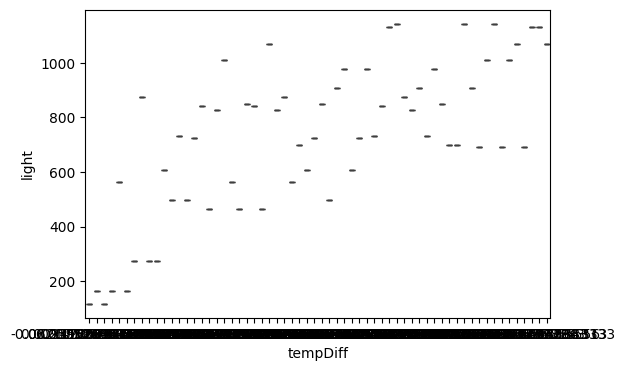

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
# 🐞 BROKEN — runs fine, tells you nothing
fig, ax = plt.subplots(figsize=(6, 4))
sns.boxplot(data=leaf, x="tempDiff", y="light", ax=ax)


plt.show()

### 🎯 Task 4 — build the real figure

`light` is a continuous measurement, so there is nothing to group by yet. **Bin it into three equal-sized bands first**, then draw a box plot of `tempDiff` for each band.

`pd.qcut(column, 3, labels=[...])` splits a column into three groups with equal numbers of samples in each.

Fill in the three blanks marked `____`.

In [ ]:
# 🎯 YOUR TURN — replace each ____
leaf["light_band"] = pd.qcut(leaf["____"], 3, labels=["Low", "Medium", "High"])

print(leaf.groupby("light_band", observed=True)[["light", "tempDiff"]].median().round(2))

LIGHT_PAL = {"Low": "#2c3e70", "Medium": "#e8a33d", "High": "#f6e27a"}   # dusk → noon

fig, ax = plt.subplots(figsize=(6.5, 4.5))
sns.boxplot(data=leaf, x="light_band", y="____", hue="light_band",
            palette=LIGHT_PAL, legend=False, width=0.55, fliersize=0, ax=ax)
sns.stripplot(data=leaf, x="light_band", y="____", color="#22223b",
              size=4, alpha=0.6, jitter=0.15, ax=ax)

ax.axhline(0, color="grey", ls="--", lw=1)      # leaf temperature == air temperature
ax.set_xlabel("Light intensity band")
ax.set_ylabel("Leaf − air temperature (°C)")
ax.set_title("Do bright leaves run hot?", loc="left", fontsize=11)
plt.show()

---
# Optional · Your own data  

## Load your own spreadsheet in 30 seconds

Run the cell, click **Choose Files**, pick a `.csv` or `.xlsx` from your computer.

In [ ]:
from google.colab import files
uploaded = files.upload()          # opens a file picker

filename = list(uploaded.keys())[0]

if filename.endswith(".csv"):
    mydata = pd.read_csv(filename)
else:
    mydata = pd.read_excel(filename)

print("Loaded", filename, "→", mydata.shape)
mydata.head()

In [ ]:
# 🎯 YOUR TURN — replace with your grouping column and your measurement column
GROUP   = "your_category_column"
MEASURE = "your_number_column"

fig, ax = plt.subplots(figsize=(7, 4.5))
sns.violinplot(data=mydata, x=GROUP, y=MEASURE, hue=GROUP,
               palette="crest", legend=False, inner="quart", cut=0, ax=ax)
sns.stripplot(data=mydata, x=GROUP, y=MEASURE, color="#22223b", size=3, alpha=0.6, ax=ax)
ax.set_title(f"{MEASURE} by {GROUP}", loc="left")
plt.show()

## Your plot, in one line

Swap in your own column names.

# The first-five-minutes checklist

Run this on any new dataset, every time.

In [ ]:
# 🎯 Change `mydata` to whichever DataFrame you want to inspect
d = mydata

print("1. SIZE      :", d.shape)
print("2. COLUMNS   :", list(d.columns))
print("\n3. TYPES — anything 'object' that should be a number is a landmine:")
print(d.dtypes.to_string())
print("\n4. MISSING VALUES:")
print(d.isna().sum()[d.isna().sum() > 0].to_string() or "   none 🎉")
print("\n5. NUMERIC SANITY CHECK — look for impossible minimums and maximums:")
display(d.describe().round(2))
print("\n6. TEXT COLUMNS — look for near-duplicates like 'Control' vs 'control ':")
for c in d.select_dtypes(exclude="number").columns[:6]:
    print(f"   {c:20s} {d[c].nunique():3d} unique → {d[c].dropna().unique()[:6]}")

---
## 🧯 When you get stuck — the five-step routine

1. **Read the bottom line.** Error type + message. Nothing above it matters yet.
2. **Find the `---->` arrow.** That is the failing line.
3. **Print the ingredients.** `print(df.columns)`, `df.dtypes`, `df["col"].unique()`, `len(df)`. Most bugs die here.
4. **Shrink the problem.** Break one long line into three short ones and run them separately.
5. **Search the message.** Paste the error type + message into Google. Someone has had it. Trim anything specific to your files first.

> **The habit that matters most:** after every step, ask *"is this number plausible?"* Python will happily hand you a confident, beautifully formatted, completely wrong answer.

---
## What you did today

| Bug | Error | Root cause | Lesson |
|---|---|---|---|
| Missing colon | `SyntaxError` | Typo | Python can't read it |
| Misspelled variable | `NameError` | Typo | No autocorrect |
| No header row | *none* | Wrong assumption | Check your row count |
| Wrong column name | `KeyError` | Case + spelling | `df.columns` |
| Mean of a text column | `TypeError` | One bad value poisons the column | `df.dtypes` |
| `astype(float)` on `"XXXXXXX"` | `ValueError` | Missing-data code | `na_values=` |
| Fused columns | `TypeError` | **Corrupt source file** | The error was a symptom |
| `== "small"` | *none* | Hidden `_` padding | Compare, then count |

| Figure | Shows | Code |
|---|---|---|
| Box plot | Five-number summary | `sns.boxplot` + `sns.stripplot` |
| Violin plot | Distribution shape | `sns.violinplot(inner="quart")` |
| Raincloud | All three at once | violin + box + scatter, layered |

---
## Resources

| Link | Why |
|---|---|
| [pandas — 10 minutes to pandas](https://pandas.pydata.org/docs/user_guide/10min.html) | The official quick start |
| [seaborn example gallery](https://seaborn.pydata.org/examples/index.html) | Find a plot you like, steal the code |
| [Python error messages explained](https://docs.python.org/3/tutorial/errors.html) | Every built-in error type |
| [From data to Viz](https://www.data-to-viz.com/) | Flowchart: which plot for which data |
| [Raincloud plots (Allen et al., 2019)](https://wellcomeopenresearch.org/articles/4-63) | The paper that popularised them |
| [UCI Machine Learning Repository](https://archive.ics.uci.edu/) | Free datasets to practise on |

